In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 8장 차원 축소

## 8.3 주성분 분석

### 8.3.2 주성분

In [2]:
from scipy.spatial.transform import Rotation

np.random.seed(42)
m = 60
X = np.zeros((m, 3))
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5
X += 0.28 * np.random.randn(m, 3)
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X += [0.2, 0, 0.2]

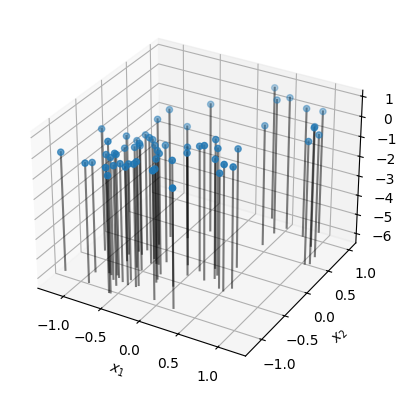

In [3]:
ax = plt.axes(projection='3d')

ax.scatter(X[:,0], X[:,1], X[:,2])
for x in X:
    ax.plot([x[0], x[0]], [x[1], x[1]], [-6, x[2]], c='k', alpha=0.5)

ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$x_3$')
plt.show()

In [4]:
X_centered = X - X.mean(axis=0)
U, s, Vt = np.linalg.svd(X_centered)
c1 = Vt[0]
c2 = Vt[1]

c1, c2

(array([0.67857588, 0.70073508, 0.22023881]),
 array([-0.72817329,  0.6811147 ,  0.07646185]))

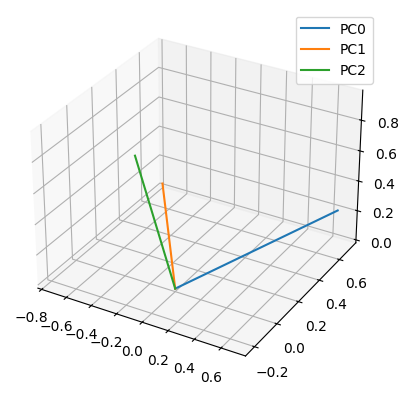

In [5]:
ax = plt.axes(projection='3d')
for i in range(3):
    ax.plot([0, Vt[i][0]], [0, Vt[i][1]], [0, Vt[i][2]], label=f'PC{i}')
plt.legend()
plt.show()

### 8.3.3 $d$차원으로 투영하기

In [6]:
W2 = Vt[:2].T
X2D_manual = X_centered @ W2

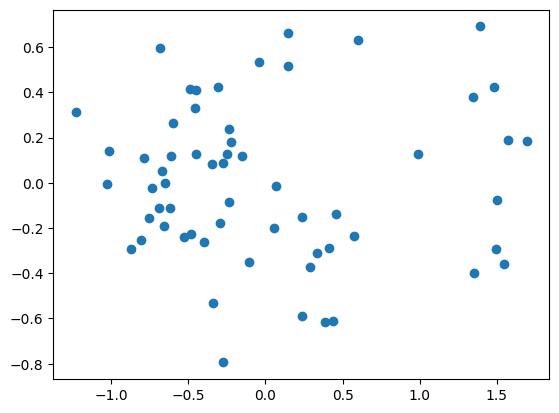

In [7]:
plt.scatter(X2D_manual[:,0], X2D_manual[:,1])
plt.show()

### 8.3.4 사이킷런 사용하기

In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X2D = pca.fit_transform(X)

In [9]:
pca.components_

array([[ 0.67857588,  0.70073508,  0.22023881],
       [ 0.72817329, -0.6811147 , -0.07646185]])

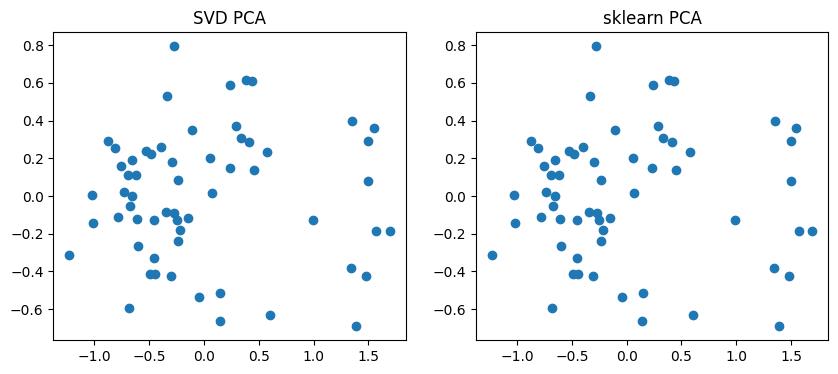

In [10]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title('SVD PCA')
plt.scatter(X2D_manual[:,0], -X2D_manual[:,1])

plt.subplot(1, 2, 2)
plt.title('sklearn PCA')
plt.scatter(X2D[:,0], X2D[:,1])

plt.show()

### 8.3.5 설명된 분산의 비율

In [11]:
pca.explained_variance_ratio_

array([0.7578477 , 0.15186921])

### 8.3.6 적절한 차원 수 선택

In [12]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

In [13]:
pca = PCA()
pca.fit(X_train)
cumsum = np.cumsum(pca.explained_variance_ratio_)

cumsum[:10]

array([0.09704664, 0.16800588, 0.22969677, 0.28359097, 0.33227894,
       0.37540125, 0.40812055, 0.4369595 , 0.4645798 , 0.4881498 ])

In [14]:
d = np.argmax(cumsum >= 0.95) + 1
d

np.int64(154)

In [15]:
pca = PCA(n_components=154)
X_reduced = pca.fit_transform(X_train)

pca.explained_variance_ratio_.sum()

np.float64(0.9501960192613034)

In [16]:
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)

pca.explained_variance_ratio_.sum()

np.float64(0.9501960192613034)

In [17]:
pca.n_components_

np.int64(154)

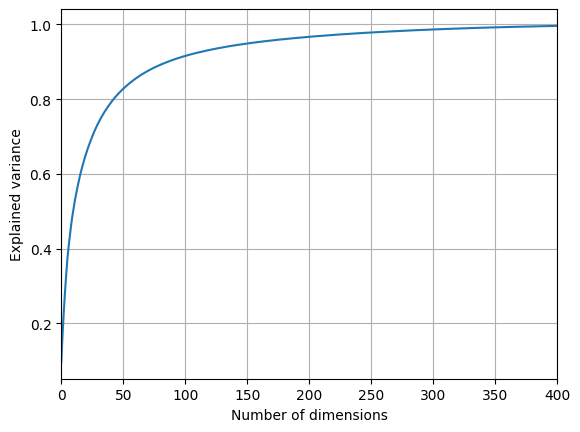

In [18]:
plt.plot(cumsum[:400])
plt.xlim(0, 400)
plt.grid()
plt.xlabel('Number of dimensions')
plt.ylabel('Explained variance')
plt.show()

In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

clf = make_pipeline(PCA(random_state=42),
                    RandomForestClassifier(random_state=42))
param_distrib = {
    'pca__n_components': np.arange(10, 80),
    'randomforestclassifier__n_estimators': np.arange(50, 500)
}
rnd_search = RandomizedSearchCV(clf, param_distrib, n_iter=20, cv=3, random_state=42)
rnd_search.fit(X_train[:1000], y_train[:1000])

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'pca__n_components': array([10, 11... 78, 79]), 'randomforestclassifier__n_estimators': array([ 50, ...97, 498, 499])}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchang

In [20]:
rnd_search.best_params_

{'randomforestclassifier__n_estimators': np.int64(272),
 'pca__n_components': np.int64(28)}

### 8.3.7 압축을 위한 PCA

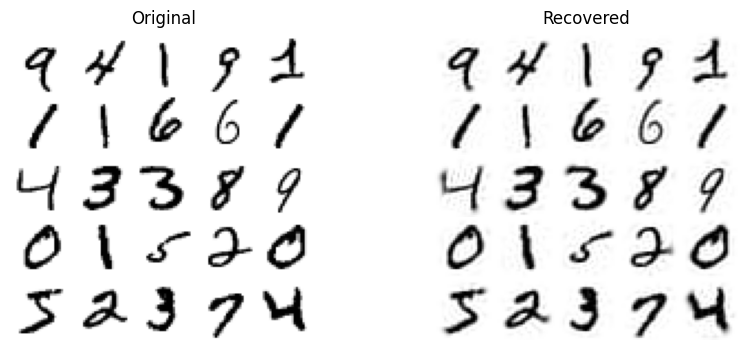

In [21]:
X_recovered = pca.inverse_transform(X_reduced)

plt.figure(figsize=(10, 4))
for i, X in enumerate((X_train, X_recovered)):
    plt.subplot(1, 2, i+1)
    plt.title(['Original', 'Recovered'][i])
    for row in range(5):
        for col in range(5):
            plt.imshow(X[row * 5 + col].reshape(28, 28), cmap="binary",
                       vmin=0, vmax=255, extent=(row, row + 1, col, col + 1))
            plt.axis([0, 5, 0, 5])
            plt.axis("off")
plt.show()

### 8.3.8 랜덤 PCA

In [22]:
rnd_pca = PCA(n_components=154, svd_solver='randomized', random_state=42)
X_reduced = rnd_pca.fit_transform(X_train)

### 8.3.9 점진적 PCA

In [23]:
from sklearn.decomposition import IncrementalPCA

n_batches = 100
inc_pca = IncrementalPCA(n_components=154)
for X_batch in np.array_split(X_train, n_batches):
    inc_pca.partial_fit(X_batch)

X_reduced = inc_pca.transform(X_train)

In [24]:
filename = '08_mnist.mmap'
X_mmap = np.memmap(filename, dtype='float32', mode='write', shape=X_train.shape)
X_mmap[:] = X_train
X_mmap.flush()

In [25]:
X_mmap = np.memmap(filename, dtype='float32', mode='readonly').reshape(-1, 784)
batch_size = X_mmap.shape[0] // n_batches
inc_pca = IncrementalPCA(n_components=154, batch_size=batch_size)
inc_pca.fit(X_mmap)

,"n_components n_components: int, default=NoneNumber of components to keep. If ``n_components`` is ``None``,then ``n_components`` is set to ``min(n_samples, n_features)``.",154
,"whiten whiten: bool, default=FalseWhen True (False by default) the ``components_`` vectors are dividedby ``n_samples`` times ``components_`` to ensure uncorrelated outputswith unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimesimprove the predictive accuracy of the downstream estimators bymaking data respect some hard-wired assumptions.",False
,"copy copy: bool, default=TrueIf False, X will be overwritten. ``copy=False`` can be used tosave memory but is unsafe for general use.",True
,"batch_size batch_size: int, default=NoneThe number of samples to use for each batch. Only used when calling``fit``. If ``batch_size`` is ``None``, then ``batch_size``is inferred from the data and set to ``5 * n_features``, to provide abalance between approximation accuracy and memory consumption.",600


## 8.4 랜덤 투영

In [26]:
from sklearn.random_projection import johnson_lindenstrauss_min_dim

m, epsilon = 5000, 0.1
d = johnson_lindenstrauss_min_dim(m, eps=epsilon)
d

np.int64(7300)

In [27]:
np.random.seed(42)
n = 20_000
P = np.random.randn(d, n) / np.sqrt(d)

X = np.random.randn(m, n)
X_reduced = X @ P.T

In [28]:
from sklearn.random_projection import GaussianRandomProjection

gaussian_rnd_proj = GaussianRandomProjection(eps=epsilon, random_state=42)
X_reduced = gaussian_rnd_proj.fit_transform(X)

In [29]:
gaussian_rnd_proj.components_

array([[ 5.81359943e-03, -1.61826124e-03,  7.58062095e-03, ...,
         4.42829826e-03,  2.00553485e-02, -1.89597272e-02],
       [ 4.07638220e-03,  3.31605183e-03, -1.09611357e-02, ...,
         7.21559891e-03,  9.53444696e-03,  4.16636507e-03],
       [-5.52267488e-03,  1.18527859e-02, -2.31960160e-03, ...,
         1.65039881e-03, -2.55380604e-02, -7.48780800e-05],
       ...,
       [-1.03564530e-02,  7.94509570e-03, -5.69474166e-03, ...,
         1.14580829e-02, -1.29950377e-02, -1.59301221e-02],
       [-6.77138686e-03, -5.90454856e-03,  1.23942811e-02, ...,
        -2.01775486e-02, -1.75452980e-03, -7.52724235e-03],
       [-4.12988138e-03,  1.24015654e-02,  3.58943880e-04, ...,
        -6.18872802e-03,  5.77292951e-04,  6.83212442e-03]],
      shape=(7300, 20000))

## 8.5 지역 선형 임베딩

In [30]:
from sklearn.datasets import make_swiss_roll

X_swiss, t = make_swiss_roll(n_samples=1000, noise=0.2, random_state=42)

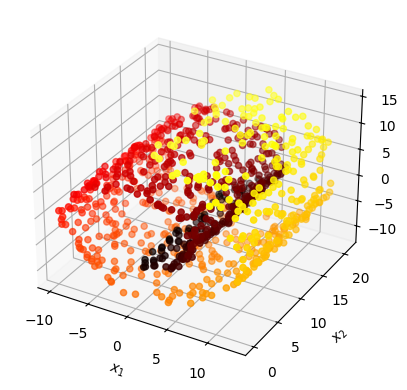

In [31]:
from matplotlib.colors import ListedColormap

darker_hot = ListedColormap(plt.cm.hot(np.linspace(0, 0.8, 256)))

ax = plt.axes(projection='3d')
ax.scatter(X_swiss[:,0], X_swiss[:,1], X_swiss[:,2], c=t, cmap=darker_hot)
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$x_3$')
plt.show()

In [32]:
from sklearn.manifold import LocallyLinearEmbedding

lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, random_state=42)
X_unrolled = lle.fit_transform(X_swiss)

In [33]:
X_unrolled.shape

(1000, 2)

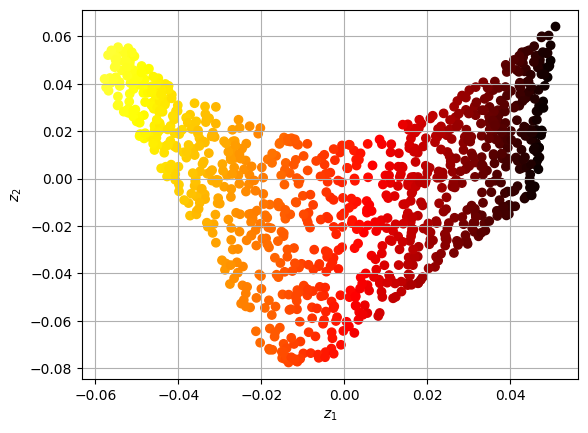

In [34]:
plt.scatter(X_unrolled[:,0], X_unrolled[:,1], c=t, cmap=darker_hot)
plt.xlabel('$z_1$')
plt.ylabel('$z_2$')
plt.grid()
plt.show()

## 연습문제

### ⑨

In [35]:
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

In [36]:
rnd_clf = RandomForestClassifier(random_state=42)

In [37]:
from sklearn.metrics import accuracy_score

%time rnd_clf.fit(X_train, y_train)

y_pred = rnd_clf.predict(X_test)
accuracy_score(y_pred, y_test)

CPU times: user 23.6 s, sys: 53.1 ms, total: 23.6 s
Wall time: 23.6 s


0.9691

In [38]:
pca = PCA(n_components=0.95, random_state=42)
X_train_reduced = pca.fit_transform(X_train, y_train)

%time rnd_clf.fit(X_train_reduced, y_train)

X_test_reduced = pca.transform(X_test)
y_pred = rnd_clf.predict(X_test_reduced)
accuracy_score(y_pred, y_test)

CPU times: user 1min 3s, sys: 115 ms, total: 1min 3s
Wall time: 1min 3s


0.9487

In [39]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)

In [40]:
%time sgd_clf.fit(X_train, y_train)

y_pred = sgd_clf.predict(X_test)
accuracy_score(y_pred, y_test)

CPU times: user 1min 50s, sys: 182 ms, total: 1min 50s
Wall time: 1min 50s


0.8674

In [41]:
%time sgd_clf.fit(X_train_reduced, y_train)

y_pred = sgd_clf.predict(X_test_reduced)
accuracy_score(y_pred, y_test)

CPU times: user 17.8 s, sys: 28 ms, total: 17.8 s
Wall time: 17.8 s


0.8931

### ⑩

In [42]:
X_sample, y_sample = mnist.data[:5000], mnist.target[:5000]

CPU times: user 1min 19s, sys: 18.9 s, total: 1min 38s
Wall time: 13 s


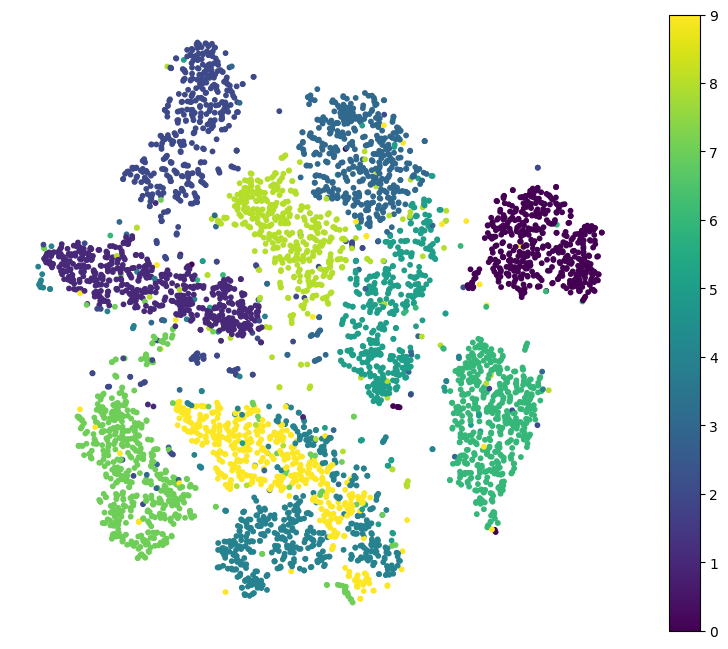

In [43]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)

%time X_reduced = tsne.fit_transform(X_sample, y_sample)

plt.figure(figsize=(10, 8))
plt.scatter(X_reduced[:,0], X_reduced[:,1], c=y_sample.astype(np.int8), s=10)
plt.colorbar()
plt.axis('off')
plt.show()

CPU times: user 148 ms, sys: 159 ms, total: 307 ms
Wall time: 44.7 ms


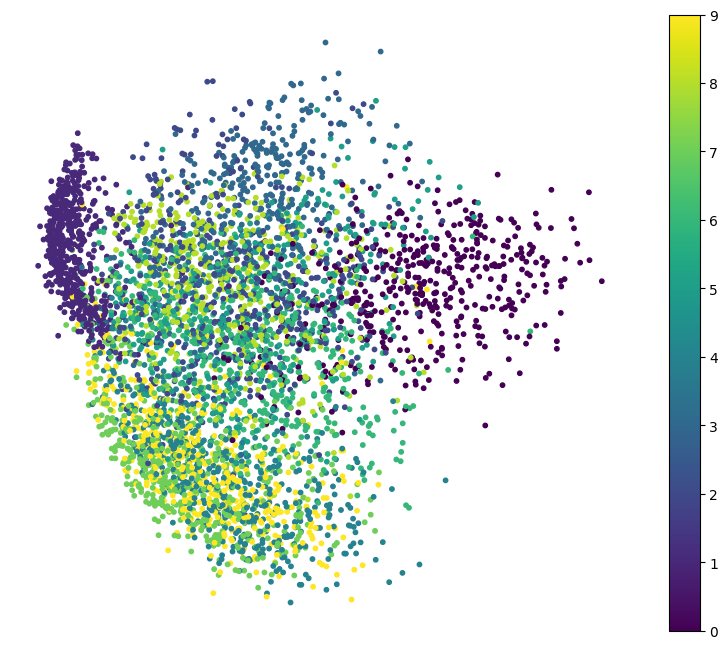

In [44]:
pca = PCA(n_components=2, random_state=42)

%time X_reduced = pca.fit_transform(X_sample, y_sample)

plt.figure(figsize=(10, 8))
plt.scatter(X_reduced[:,0], X_reduced[:,1], c=y_sample.astype(np.int8), s=10)
plt.colorbar()
plt.axis('off')
plt.show()

CPU times: user 4.37 s, sys: 955 ms, total: 5.33 s
Wall time: 2.83 s


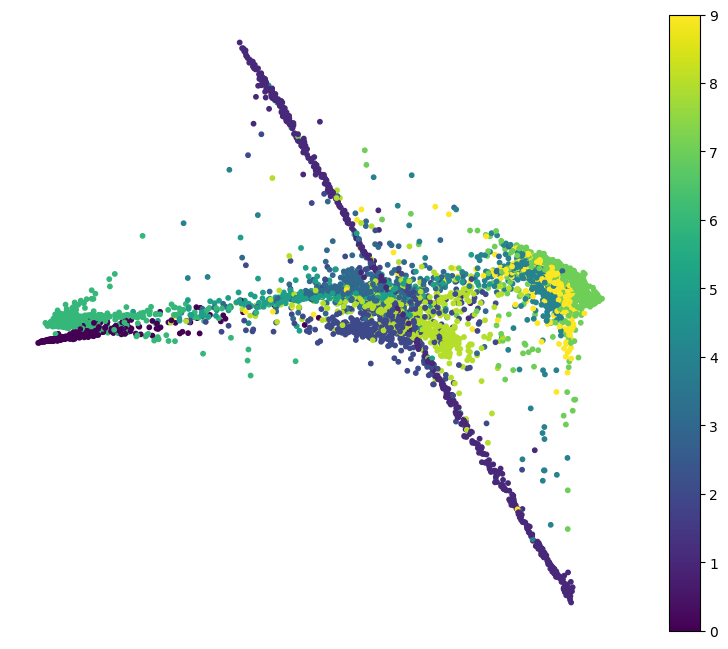

In [45]:
lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10)

%time X_reduced = lle.fit_transform(X_sample, y_sample)

plt.figure(figsize=(10, 8))
plt.scatter(X_reduced[:,0], X_reduced[:,1], c=y_sample.astype(np.int8), s=10)
plt.colorbar()
plt.axis('off')
plt.show()